In [12]:
%%writefile /kaggle/working/sgutils.py
import numpy as np
import pandas as pd

DATA_DIR  = "/kaggle/input/competitions/industrial-surface-defect-detection/public"
TRAIN_DIR = f"{DATA_DIR}/train"
TEST_DIR  = f"{DATA_DIR}/test"
CLASSES   = ["defect_a", "defect_b", "defect_c", "defect_d"]
H, W      = 128, 800
SEED      = 42
EMPTY_RLE = " "     

def is_empty_rle(s):
    return pd.isna(s) or str(s).strip() == ""

def rle_decode(rle):
    flat = np.zeros(H * W, dtype=np.uint8)
    if not is_empty_rle(rle):
        a = np.array(str(rle).split(), dtype=np.int64)
        for start, length in zip(a[0::2] - 1, a[1::2]): 
            flat[start:start + length] = 1
    return flat.reshape((H, W), order="F")

def rle_encode(mask):
    assert mask.shape == (H, W), f"bad shape {mask.shape}"
    flat = np.concatenate([[0], mask.astype(np.uint8).flatten(order="F"), [0]])
    edges = np.where(flat[1:] != flat[:-1])[0] + 1       
    edges[1::2] -= edges[0::2]                           
    return " ".join(map(str, edges)) or EMPTY_RLE

def load_tables():
    train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
    sub_df = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")
    train_df["is_pos"] = ~train_df.mask_rle.map(is_empty_rle)
    return train_df, sub_df

def pair_stats(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool)
    return np.stack([(pred & gt).sum(axis=(2, 3)),
                     pred.sum(axis=(2, 3)),
                     gt.sum(axis=(2, 3))], axis=-1)

def competition_score(S):
    inter, ps, gs = (S[..., k].astype(float) for k in range(3))
    pos, emp = gs > 0, gs == 0
    dice = 2 * inter / np.maximum(ps + gs, 1)

    fg_dice   = dice[pos].mean()
    empty_acc = (ps[emp] == 0).mean()
    fp_score  = (1 - ps[emp] / (H * W)).mean()
    out = dict(
        score      = 0.70 * fg_dice + 0.20 * fp_score + 0.10 * empty_acc,
        fg_dice    = fg_dice,
        fp_score   = fp_score,
        empty_acc  = empty_acc,
        dice_naive = np.where(pos, dice, (ps == 0).astype(float)).mean(), 
        pixel_acc  = (1 - (ps + gs - 2 * inter) / (H * W)).mean(),       
    )
    for j, c in enumerate(CLASSES):
        out[f"dice_{c}"]  = dice[pos[:, j], j].mean()
        out[f"empty_{c}"] = (ps[emp[:, j], j] == 0).mean()
    return out

Overwriting /kaggle/working/sgutils.py


In [13]:
import sys, importlib
sys.path.insert(0, "/kaggle/working")
import sgutils; importlib.reload(sgutils)
from sgutils import *

train_df, sub_df = load_tables()

assert rle_encode(np.zeros((H, W), np.uint8)) == EMPTY_RLE
assert rle_encode(np.ones((H, W), np.uint8)) == "1 102400"
assert rle_decode(np.nan).sum() == 0 and rle_decode(" ").sum() == 0

pos = train_df[train_df.is_pos]
bad = sum(rle_encode(rle_decode(s)) != s.strip() for s in pos.mask_rle)
print(f"Round trip: {len(pos) - bad} / {len(pos)} match")
assert bad == 0
print("sgutils OK")

Round trip: 7201 / 7201 match
sgutils OK


In [14]:
import os, importlib, torch 
import random, cv2
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np, pandas as pd
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
pos = train_df[train_df.is_pos]          

In [15]:

assert set(train_df.defect_type) == set(CLASSES)
assert not train_df.duplicated(["image_id", "defect_type"]).any()
assert (train_df.groupby("image_id").size() == 4).all()        
assert (train_df.width == W).all() and (train_df.height == H).all()

stems = lambda d: {os.path.splitext(f)[0] for f in os.listdir(d)}
train_ids, test_ids = set(train_df.image_id), set(sub_df.image_id)
assert train_ids == stems(TRAIN_DIR) and test_ids == stems(TEST_DIR)
assert not (train_ids & test_ids)                               
assert (sub_df.ID.values == np.arange(1, len(sub_df) + 1)).all()
assert (sub_df.defect_type.values == np.tile(CLASSES, len(sub_df) // 4)).all()

ims = [Image.open(f"{TRAIN_DIR}/{i}.jpg") for i in random.sample(sorted(train_ids), 200)]
assert {(m.height, m.width) for m in ims} == {(H, W)}
print("Modes:", {m.mode for m in ims}, "| all checks passed")

Modes: {'RGB'} | all checks passed


In [16]:
print(train_df.groupby("defect_type").is_pos.agg(positive="sum", rate="mean").round(3))
print(f"\nPositive (image, class) pairs: {train_df.is_pos.mean():.1%}")

print("\nImages by number of defect classes present:")
print(train_df.groupby("image_id").is_pos.sum().value_counts().sort_index())

wide = train_df.pivot(index="image_id", columns="defect_type", values="is_pos")[CLASSES].astype(int)
print("\nCo-occurrence:\n", wide.T.dot(wide))

             positive   rate
defect_type                 
defect_a         1081  0.095
defect_b          313  0.027
defect_c         4100  0.360
defect_d         1707  0.150

Positive (image, class) pairs: 15.8%

Images by number of defect classes present:
is_pos
0    5516
1    4679
2    1072
3     126
Name: count, dtype: int64

Co-occurrence:
 defect_type  defect_a  defect_b  defect_c  defect_d
defect_type                                        
defect_a         1081        42       310       234
defect_b           42       313        95        64
defect_c          310        95      4100       705
defect_d          234        64       705      1707


min start: 1 | max end: 102400 (H*W = 102400)
Mean components: column-major 2.0 | row-major 49.3


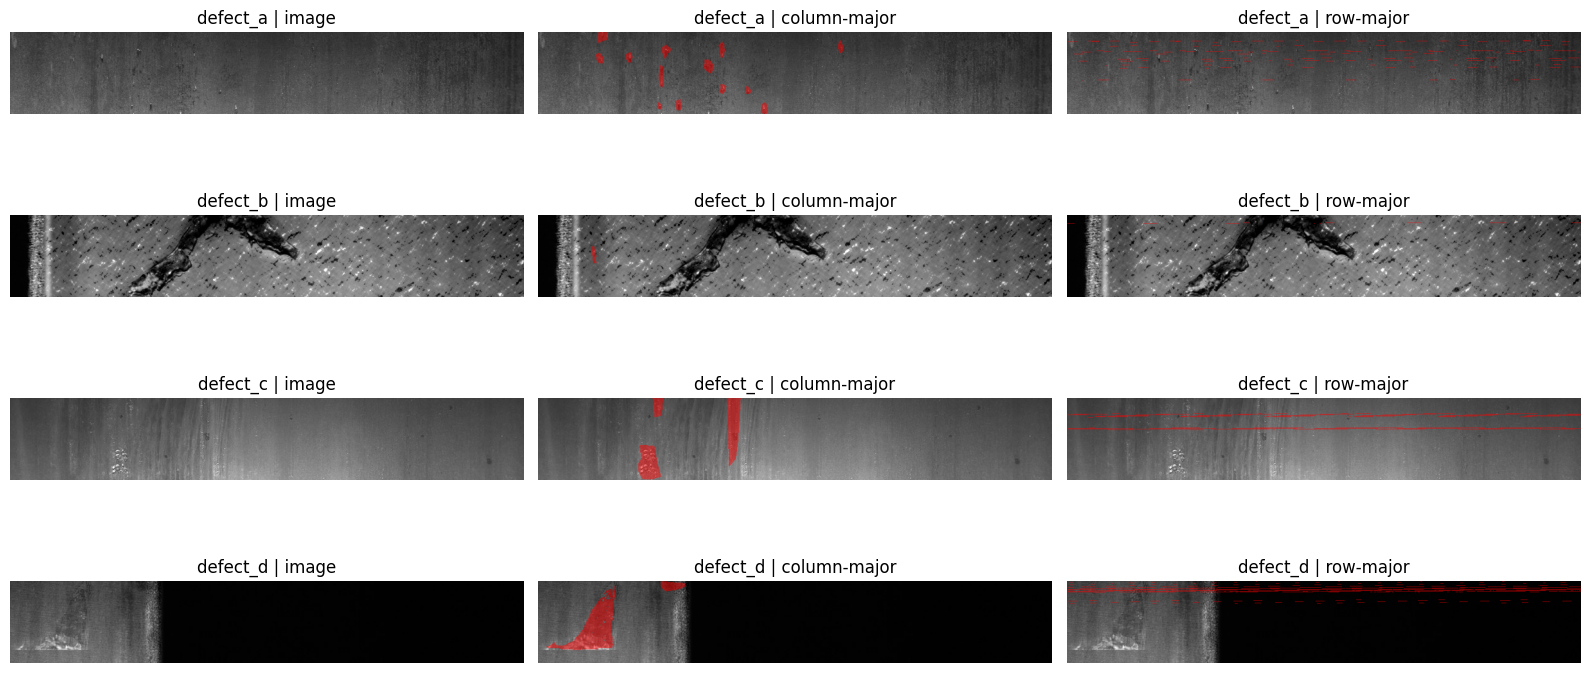

In [17]:
runs = [np.array(s.split(), dtype=np.int64) for s in pos.mask_rle]
print("min start:", min(a[0::2].min() for a in runs),
      "| max end:", max((a[0::2] + a[1::2] - 1).max() for a in runs), f"(H*W = {H*W})")

def decode_rowmajor(s):
    return rle_decode(s).flatten(order="F").reshape(H, W)

n_comp = lambda m: cv2.connectedComponents(m, connectivity=8)[0] - 1
sample = pos.sample(300, random_state=SEED)
cF = np.array([n_comp(rle_decode(s)) for s in sample.mask_rle])
cC = np.array([n_comp(decode_rowmajor(s)) for s in sample.mask_rle])
print(f"Mean components: column-major {cF.mean():.1f} | row-major {cC.mean():.1f}")

def overlay(img, m):
    out = img.astype(np.float32)
    out[m == 1] = 0.5 * out[m == 1] + 0.5 * np.array([255, 0, 0])
    return out.astype(np.uint8)

fig, ax = plt.subplots(4, 3, figsize=(16, 8))
for r, c in enumerate(CLASSES):
    row = pos[pos.defect_type == c].sample(1, random_state=SEED + r).iloc[0]
    img = np.array(Image.open(f"{TRAIN_DIR}/{row.image_id}.jpg").convert("RGB"))
    for k, (t, m) in enumerate([("image", None), ("column-major", rle_decode(row.mask_rle)),
                                ("row-major", decode_rowmajor(row.mask_rle))]):
        ax[r, k].imshow(img if m is None else overlay(img, m)); ax[r, k].axis("off")
        ax[r, k].set_title(f"{c} | {t}")
plt.tight_layout(); plt.show()

                  defect_a  defect_b  defect_c  defect_d
masks               1081.0     313.0    4100.0    1707.0
median area (px)     472.0     620.0    2313.0    5143.0
median area (%)        0.5       0.6       2.3       5.0
% with >1 blob        27.2       8.0      52.0      31.5
median bbox h         33.0      87.0     111.0      74.0
median bbox w         15.0      10.0      24.0     100.0


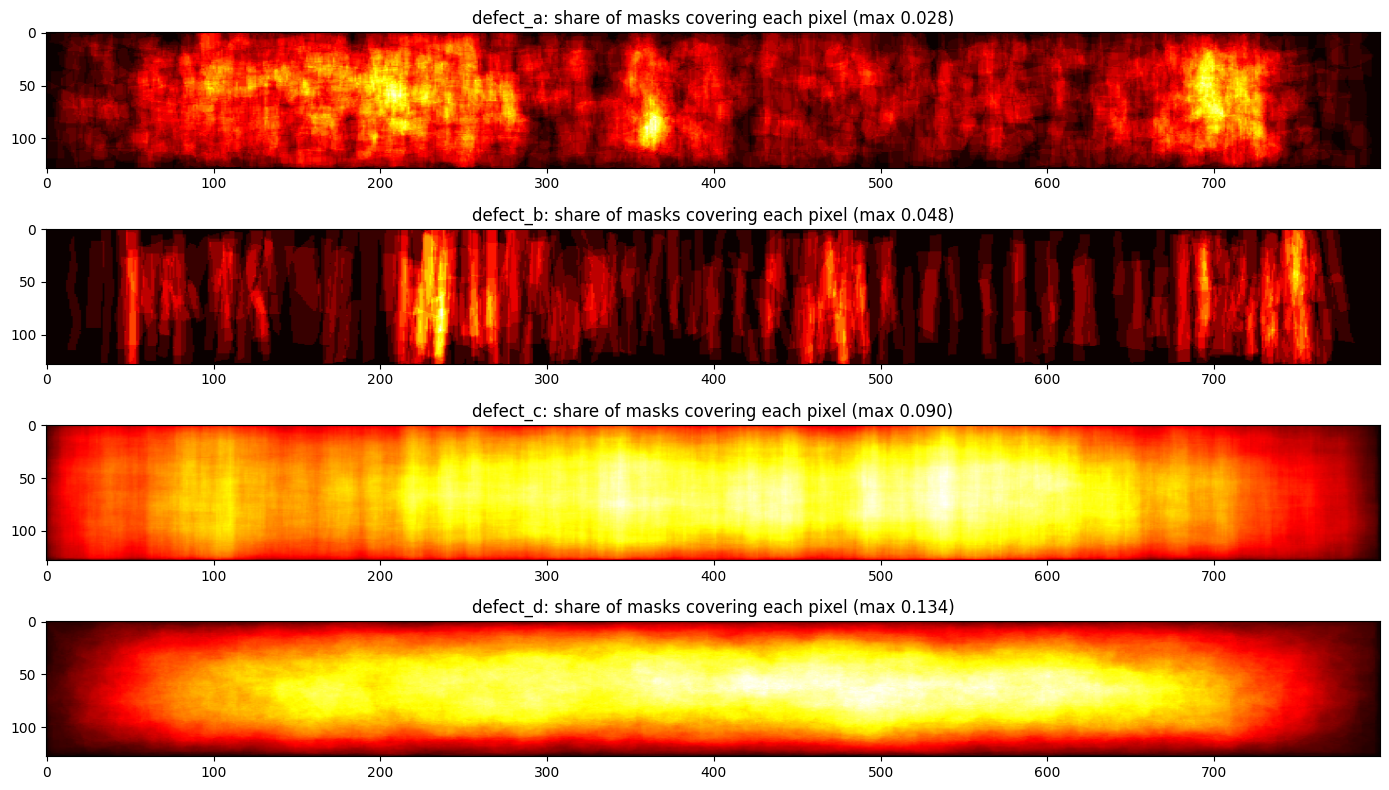

In [18]:
stats = {c: dict(area=[], ncomp=[], bh=[], bw=[]) for c in CLASSES}
heat = {c: np.zeros((H, W)) for c in CLASSES}

for r in pos.itertuples():
    m = rle_decode(r.mask_rle)
    n, _, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    big = 1 + st[1:, cv2.CC_STAT_AREA].argmax()         
    s = stats[r.defect_type]
    s["area"].append(m.sum()); s["ncomp"].append(n - 1)
    s["bh"].append(st[big, cv2.CC_STAT_HEIGHT]); s["bw"].append(st[big, cv2.CC_STAT_WIDTH])
    heat[r.defect_type] += m

summary = pd.DataFrame({c: {
    "masks": len(s["area"]),
    "median area (px)": np.median(s["area"]),
    "median area (%)": 100 * np.median(s["area"]) / (H * W),
    "% with >1 blob": 100 * np.mean(np.array(s["ncomp"]) > 1),
    "median bbox h": np.median(s["bh"]),
    "median bbox w": np.median(s["bw"]),
} for c, s in stats.items()}).round(1)
print(summary)

fig, ax = plt.subplots(4, 1, figsize=(14, 8))
for a, c in zip(ax, CLASSES):
    hm = heat[c] / len(stats[c]["area"])
    a.imshow(hm, aspect="auto", cmap="hot"); a.set_title(f"{c}: share of masks covering each pixel (max {hm.max():.3f})")
plt.tight_layout(); plt.show()

In [19]:
from sklearn.model_selection import train_test_split

present = train_df.pivot(index="image_id", columns="defect_type", values="is_pos")[CLASSES]
combo = present.apply(lambda r: "+".join(c for c in CLASSES if r[c]) or "clean", axis=1)
print("unique combinations:", combo.nunique())
print(combo.value_counts())

print("defect_b in val (exact 80/20):", round((present["defect_b"].groupby(combo).sum() * 0.20).sum(), 2))

counts = combo.value_counts()
strata = combo.where(combo.map(counts) >= 2, "rare_merged")
assert strata.value_counts().min() >= 2
print("images in merged singleton bucket:", (strata == "rare_merged").sum())

ids = combo.index.to_numpy()
_, va = train_test_split(ids, test_size=0.20, random_state=SEED, stratify=strata.loc[ids])

split = pd.DataFrame({"image_id": ids, "combo": combo.loc[ids].values})
split["fold"] = np.where(split.image_id.isin(set(va)), "val", "train")

os.makedirs("/kaggle/working/splits", exist_ok=True)
SPLIT_PATH = f"/kaggle/working/splits/split_combo_seed{SEED}.csv"
split.sort_values("image_id").to_csv(SPLIT_PATH, index=False)

chk = pd.read_csv(SPLIT_PATH)
assert chk.image_id.is_unique and set(chk.image_id) == set(train_df.image_id)
print(chk.fold.value_counts().to_dict())
print(train_df.assign(fold=train_df.image_id.map(chk.set_index("image_id").fold))
      .groupby(["defect_type", "fold"]).is_pos.sum().unstack())

unique combinations: 15
clean                         5516
defect_c                      3105
defect_d                       822
defect_a                       601
defect_c+defect_d              598
defect_a+defect_c              215
defect_b                       151
defect_a+defect_d              136
defect_a+defect_c+defect_d      87
defect_b+defect_c               67
defect_b+defect_d               33
defect_a+defect_b               23
defect_b+defect_c+defect_d      20
defect_a+defect_b+defect_d      11
defect_a+defect_b+defect_c       8
Name: count, dtype: int64
defect_b in val (exact 80/20): 62.6
images in merged singleton bucket: 0
{'train': 9114, 'val': 2279}
fold         train  val
defect_type            
defect_a       865  216
defect_b       250   63
defect_c      3280  820
defect_d      1365  342


In [20]:
split  = pd.read_csv(SPLIT_PATH)
val_ids = sorted(split[split.fold == "val"].image_id)[:300]
rle = train_df.set_index(["image_id", "defect_type"]).mask_rle
gt = np.stack([np.stack([rle_decode(rle[(i, c)]) for c in CLASSES]) for i in val_ids])
print("gt:", gt.shape, "| positive pairs:", (gt.sum((2, 3)) > 0).sum(), "of", gt.shape[0] * 4)

show = lambda name, S: print(f"{name:22s}", {k: round(float(v), 4) for k, v in competition_score(S).items()
                                              if k in ("score", "fg_dice", "fp_score", "empty_acc", "pixel_acc")})

r = competition_score(pair_stats(gt, gt)); show("perfect", pair_stats(gt, gt))
assert abs(r["score"] - 1) < 1e-9

S0 = pair_stats(np.zeros_like(gt), gt); r = competition_score(S0); show("all empty", S0)
assert r["fg_dice"] == 0 and r["empty_acc"] == 1 and r["fp_score"] == 1
assert abs(r["score"] - 0.30) < 1e-9

S1 = pair_stats(np.ones_like(gt), gt); r = competition_score(S1); show("all ones", S1)
assert r["empty_acc"] == 0 and r["fp_score"] == 0

fp = gt.copy()
fp[gt.sum((2, 3)) == 0, :10, :10] = 1
S2 = pair_stats(fp, gt); r = competition_score(S2); show("perfect + tiny FP blob", S2)
assert r["fg_dice"] == 1 and r["empty_acc"] == 0

miss = gt.copy(); miss[:, 3] = 0
S3 = pair_stats(miss, gt); r = competition_score(S3); show("miss defect_d", S3)
assert r["dice_defect_d"] == 0 and r["dice_defect_a"] == 1
print("\nEvaluator tests passed.")

gt: (300, 4, 128, 800) | positive pairs: 205 of 1200
perfect                {'score': 1.0, 'fg_dice': 1.0, 'fp_score': 1.0, 'empty_acc': 1.0, 'pixel_acc': 1.0}
all empty              {'score': 0.3, 'fg_dice': 0.0, 'fp_score': 1.0, 'empty_acc': 1.0, 'pixel_acc': 0.9908}
all ones               {'score': 0.0641, 'fg_dice': 0.0916, 'fp_score': 0.0, 'empty_acc': 0.0, 'pixel_acc': 0.0092}
perfect + tiny FP blob {'score': 0.8998, 'fg_dice': 1.0, 'fp_score': 0.999, 'empty_acc': 0.0, 'pixel_acc': 0.9992}
miss defect_d          {'score': 0.8327, 'fg_dice': 0.761, 'fp_score': 1.0, 'empty_acc': 1.0, 'pixel_acc': 0.9973}

Evaluator tests passed.


In [21]:
# course guide 7.1: 8 positive pairs (five at Dice 0.9, three at 0.5) and 12 empty pairs (two with 512-px blobs)
rows = [(90, 100, 100)] * 5 + [(50, 100, 100)] * 3 + [(0, 0, 0)] * 10 + [(0, 512, 0)] * 2
r = competition_score(np.array(rows).reshape(5, 4, 3))
assert round(r["score"], 4) == 0.8082
print("Guide example 7.1 reproduced:", round(r["score"], 4))

Guide example 7.1 reproduced: 0.8082
